# QSAR Mito — Graphormer & GraphGPS

This notebook trains two advanced graph transformer architectures on the mito dataset and compares them against the baselines from `QSAR-Mito.ipynb`.

| Model | Key idea |
|---|---|
| **Graphormer** (Ying et al., NeurIPS 2021) | Centrality encoding (degree bias) + multi-head self-attention via TransformerConv |
| **GraphGPS** (Rampášek et al., NeurIPS 2022) | Local MPNN (GINEConv) + global Transformer attention + Laplacian eigenvector PE |

Same data file, atom/bond features, 80/10/10 split (random_state=42), and base hyperparameters (`hidden_channels=64`, `lr=0.001`, `batch_size=32`, `epochs=50`) as the original notebook.

In [1]:
!pip install torch torch-geometric scipy

In [2]:
import pandas as pd
import numpy as np
import itertools
import torch
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem
from rdkit.Chem import AllChem, PandasTools
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import (TransformerConv, GINEConv, GPSConv,
                                  global_add_pool)
from torch_geometric.utils import (degree as pyg_degree,
                                    get_laplacian, to_dense_adj)
from torch.nn import Linear, Sequential
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tqdm.notebook import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


## Load data and build molecular graphs
Identical to `QSAR-Mito.ipynb`: same Excel file, same atom features (5-dim), same bond features (3-dim).

In [3]:
df = pd.read_excel('AID_720635_cleaned.xlsx',
                   usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES',
                            'PUBCHEM_ACTIVITY_SCORE', 'PUBCHEM_ACTIVITY_OUTCOME'])
PandasTools.AddMoleculeColumnToFrame(df, 'PUBCHEM_EXT_DATASOURCE_SMILES', 'Molecule')
df_cleaned = df.dropna(subset=['Molecule'])
print(f'Loaded {len(df_cleaned)} valid molecules.')

# ── atom / bond feature functions (same as original notebook) ────────────────
def atom_features(atom):
    return torch.tensor([
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetFormalCharge(),
        int(atom.GetHybridization()),
        int(atom.GetIsAromatic())
    ], dtype=torch.float)

def bond_features(bond):
    return torch.tensor([
        int(bond.GetBondType()),
        int(bond.GetStereo()),
        int(bond.GetIsConjugated())
    ], dtype=torch.float)

# ── build graph list ─────────────────────────────────────────────────────────
data_list = []
for _, row in df_cleaned.iterrows():
    mol = row['Molecule']
    if mol is None:
        continue
    x = torch.stack([atom_features(a) for a in mol.GetAtoms()])
    edge_index, edge_attr = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_features(bond)
        edge_index += [[i, j], [j, i]]
        edge_attr  += [bf, bf]
    if not edge_index:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr  = torch.empty((0, 3), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
        edge_attr  = torch.stack(edge_attr)
    y = torch.tensor([row['PUBCHEM_ACTIVITY_SCORE']], dtype=torch.float)
    data_list.append(Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y))

print(f'Graph objects: {len(data_list)}')
print(f'Example — nodes: {data_list[0].num_nodes}, edges: {data_list[0].num_edges}')

[22:12:49] WARNING: not removing hydrogen atom without neighbors
[22:12:49] WARNING: not removing hydrogen atom without neighbors
[22:12:49] WARNING: not removing hydrogen atom without neighbors


Loaded 8099 valid molecules.
Graph objects: 8099
Example — nodes: 5, edges: 8


## Compute Laplacian eigenvector PE (for GraphGPS)

GraphGPS uses Laplacian eigenvectors as positional encodings (PE) — a **global PE** that tells each node where it sits in the graph. We compute the `k` smallest non-trivial eigenvectors of the normalised Laplacian and store them as an extra node attribute `pe`.

In [4]:
PE_DIM = 8  # number of eigenvectors

def compute_laplacian_pe(data, k=PE_DIM):
    n = data.num_nodes
    if n <= 2:
        return torch.zeros(n, k)
    ei, ew = get_laplacian(data.edge_index, normalization='sym', num_nodes=n)
    L = to_dense_adj(ei, edge_attr=ew, max_num_nodes=n).squeeze(0).numpy()
    try:
        _, vecs = np.linalg.eigh(L)          # ascending eigenvalue order
        num_take = min(k, n - 1)             # skip trivial eigenvector at index 0
        pe = torch.from_numpy(vecs[:, 1:1 + num_take]).float()
        if pe.shape[1] < k:                  # pad if graph is tiny
            pe = F.pad(pe, (0, k - pe.shape[1]))
    except Exception:
        pe = torch.zeros(n, k)
    return pe

# Build a second graph list that includes the PE attribute (for GraphGPS)
data_list_gps = []
for d in data_list:
    pe = compute_laplacian_pe(d)
    data_list_gps.append(
        Data(x=d.x, edge_index=d.edge_index, edge_attr=d.edge_attr, y=d.y, pe=pe)
    )

print(f'Laplacian PE (dim={PE_DIM}) computed for {len(data_list_gps)} graphs.')
print(f'PE shape of first graph: {data_list_gps[0].pe.shape}')

Laplacian PE (dim=8) computed for 8099 graphs.
PE shape of first graph: torch.Size([5, 8])


## Split data — 80 / 10 / 10
Same proportions and `random_state=42` as `QSAR-Mito.ipynb`.

In [5]:
# ── Graphormer splits ────────────────────────────────────────────────────────
d_tmp,  d_test  = train_test_split(data_list,     test_size=0.1,  random_state=42)
d_train, d_val  = train_test_split(d_tmp,         test_size=1/9,  random_state=42)

# ── GraphGPS splits (same indices, includes PE) ──────────────────────────────
g_tmp,  g_test  = train_test_split(data_list_gps, test_size=0.1,  random_state=42)
g_train, g_val  = train_test_split(g_tmp,         test_size=1/9,  random_state=42)

print(f'Train: {len(d_train)}  Val: {len(d_val)}  Test: {len(d_test)}')

Train: 6479  Val: 810  Test: 810


In [6]:
BATCH_SIZE = 32   # same as original
HIDDEN_CHANNELS = 64
LR = 0.001
EPOCHS = 50
DROPOUT = 0.5
NUM_FEATURES = d_train[0].x.shape[1]   # 5 atom features

# Graphormer loaders
train_loader = DataLoader(d_train, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(d_val,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(d_test,  batch_size=BATCH_SIZE, shuffle=False)

# GraphGPS loaders (include PE)
train_loader_gps = DataLoader(g_train, batch_size=BATCH_SIZE, shuffle=True)
val_loader_gps   = DataLoader(g_val,   batch_size=BATCH_SIZE, shuffle=False)
test_loader_gps  = DataLoader(g_test,  batch_size=BATCH_SIZE, shuffle=False)

print(f'num_features={NUM_FEATURES}, hidden_channels={HIDDEN_CHANNELS}, '
      f'lr={LR}, batch_size={BATCH_SIZE}, epochs={EPOCHS}')

num_features=5, hidden_channels=64, lr=0.001, batch_size=32, epochs=50


---
## Graphormer

**Paper**: *Do Transformers Really Perform Badly for Graph Representation?* (Ying et al., NeurIPS 2021)

Key components implemented here:
1. **Centrality encoding** — node degree is embedded and added to the node representation before attention, giving the model an inductive bias about graph connectivity.
2. **Multi-head self-attention** — `TransformerConv` layers with edge features (attention scores are conditioned on bond type / stereo / conjugation).
3. **Transformer architecture** — layer norm + FFN with residual connections after each attention layer.

In [7]:
class GraphormerLayer(nn.Module):
    """One Graphormer-style block: multi-head attention → LN+residual → FFN → LN+residual."""

    def __init__(self, hidden_channels, num_heads, edge_dim=3, dropout=0.5):
        super().__init__()
        assert hidden_channels % num_heads == 0
        head_dim = hidden_channels // num_heads
        self.attn = TransformerConv(
            in_channels=hidden_channels,
            out_channels=head_dim,
            heads=num_heads,
            concat=True,
            edge_dim=edge_dim,
            dropout=dropout,
            beta=True,          # learned interpolation between root and aggregated
        )
        self.norm1 = nn.LayerNorm(hidden_channels)
        self.ffn = nn.Sequential(
            Linear(hidden_channels, hidden_channels * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            Linear(hidden_channels * 2, hidden_channels),
        )
        self.norm2 = nn.LayerNorm(hidden_channels)
        self.drop  = nn.Dropout(dropout)

    def forward(self, x, edge_index, edge_attr):
        x = self.norm1(x + self.drop(self.attn(x, edge_index, edge_attr)))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x


class GraphormerModel(nn.Module):
    """Graph Transformer with centrality (degree) encoding and multi-head attention."""

    def __init__(self, num_features, hidden_channels,
                 num_heads=4, num_layers=2, dropout=0.5, num_classes=1):
        super().__init__()
        torch.manual_seed(42)

        self.node_emb   = Linear(num_features, hidden_channels)
        self.degree_emb = nn.Embedding(100, hidden_channels)  # centrality encoding

        self.layers = nn.ModuleList([
            GraphormerLayer(hidden_channels, num_heads,
                            edge_dim=3, dropout=dropout)
            for _ in range(num_layers)
        ])

        self.drop    = nn.Dropout(dropout)
        self.lin_out = Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, edge_attr, batch):
        # Node embedding
        h = self.node_emb(x)

        # Centrality encoding: embed node degree and add
        deg = pyg_degree(edge_index[0], num_nodes=x.size(0)).long().clamp(max=99)
        h   = h + self.degree_emb(deg)
        h   = F.relu(h)
        h   = self.drop(h)

        # Graphormer transformer layers
        for layer in self.layers:
            h = layer(h, edge_index, edge_attr)

        # Global pooling → regression head
        h = global_add_pool(h, batch)
        return self.lin_out(h)


print('GraphormerModel defined.')

GraphormerModel defined.


### Train / evaluate helpers

In [8]:
loss_fn = nn.MSELoss()

def train_epoch(model, optimizer, loader, has_pe=False):
    model.train()
    total_loss = 0
    for data in loader:
        data = data.to(device)
        optimizer.zero_grad()
        if has_pe:
            out = model(data.x, data.edge_index, data.edge_attr, data.batch, data.pe)
        else:
            out = model(data.x, data.edge_index, data.edge_attr, data.batch)
        loss = loss_fn(out.squeeze(), data.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(loader.dataset)


def evaluate(model, loader, has_pe=False):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            if has_pe:
                out = model(data.x, data.edge_index, data.edge_attr, data.batch, data.pe)
            else:
                out = model(data.x, data.edge_index, data.edge_attr, data.batch)
            preds.append(out.squeeze().cpu())
            targets.append(data.y.cpu())
    preds   = torch.cat(preds).numpy()
    targets = torch.cat(targets).numpy()
    return {
        'r2':   r2_score(targets, preds),
        'mae':  mean_absolute_error(targets, preds),
        'rmse': float(np.sqrt(mean_squared_error(targets, preds))),
    }

print('Train / evaluate helpers defined.')

Train / evaluate helpers defined.


### Hyperparameter search — Graphormer
Grid over `num_heads` and `num_layers`; all other settings match the original notebook.

In [9]:
param_grid_graphormer = {
    'num_heads':  [2, 4],
    'num_layers': [2, 3],
}

best_val_r2_graphormer  = -float('inf')
best_graphormer_params  = None
best_graphormer_state   = None
best_graphormer_val     = {}

for num_heads, num_layers in itertools.product(
        param_grid_graphormer['num_heads'],
        param_grid_graphormer['num_layers']):

    params = {'num_heads': num_heads, 'num_layers': num_layers, 'dropout': DROPOUT}
    print(f'\nGraphormer  num_heads={num_heads}  num_layers={num_layers}')

    model = GraphormerModel(
        num_features=NUM_FEATURES,
        hidden_channels=HIDDEN_CHANNELS,
        num_heads=num_heads,
        num_layers=num_layers,
        dropout=DROPOUT,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    for epoch in tqdm(range(1, EPOCHS + 1), desc='epochs'):
        train_epoch(model, optimizer, train_loader, has_pe=False)

    val_metrics = evaluate(model, val_loader, has_pe=False)
    print(f'  Val  R²={val_metrics["r2"]:.4f}  '
          f'MAE={val_metrics["mae"]:.4f}  RMSE={val_metrics["rmse"]:.4f}')

    if val_metrics['r2'] > best_val_r2_graphormer:
        best_val_r2_graphormer = val_metrics['r2']
        best_graphormer_params = params
        best_graphormer_state  = {k: v.clone() for k, v in model.state_dict().items()}
        best_graphormer_val    = val_metrics

print(f'\n── Best Graphormer hyperparameters ─────────────────────────────')
print(f'  {best_graphormer_params}')
print(f'  Val R²={best_val_r2_graphormer:.4f}')


Graphormer  num_heads=2  num_layers=2


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=0.0902  MAE=17.2126  RMSE=23.1086

Graphormer  num_heads=2  num_layers=3


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=0.0826  MAE=16.6202  RMSE=23.2048

Graphormer  num_heads=4  num_layers=2


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=0.0617  MAE=17.4246  RMSE=23.4679

Graphormer  num_heads=4  num_layers=3


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=0.0847  MAE=17.2689  RMSE=23.1785

── Best Graphormer hyperparameters ─────────────────────────────
  {'num_heads': 2, 'num_layers': 2, 'dropout': 0.5}
  Val R²=0.0902


In [10]:
# Load best checkpoint and evaluate on held-out test set
best_graphormer = GraphormerModel(
    num_features=NUM_FEATURES,
    hidden_channels=HIDDEN_CHANNELS,
    num_heads=best_graphormer_params['num_heads'],
    num_layers=best_graphormer_params['num_layers'],
    dropout=DROPOUT,
).to(device)
best_graphormer.load_state_dict(best_graphormer_state)

graphormer_test = evaluate(best_graphormer, test_loader, has_pe=False)

print('Graphormer — Test Set Performance')
print(f'  R²:   {graphormer_test["r2"]:.4f}')
print(f'  MAE:  {graphormer_test["mae"]:.4f}')
print(f'  RMSE: {graphormer_test["rmse"]:.4f}')
print(f'  Best params: {best_graphormer_params}')

Graphormer — Test Set Performance
  R²:   0.1887
  MAE:  16.1190
  RMSE: 21.5117
  Best params: {'num_heads': 2, 'num_layers': 2, 'dropout': 0.5}


---
## GraphGPS

**Paper**: *Recipe for a General, Powerful, Scalable Graph Transformer* (Rampášek et al., NeurIPS 2022)

Architecture follows the GPS recipe:
1. **Positional encoding** — Laplacian eigenvectors (`pe_dim=8`) projected and added to node features before any GPS layer.
2. **Local message passing** — `GINEConv` (edge-feature-aware GIN) aggregates information from chemical bond neighbours.
3. **Global attention** — standard `MultiheadAttention` attends over *all* atoms in a molecule simultaneously, decoupled from the graph structure.
4. **GPS layer** combines outputs of (2) and (3) with layer normalisation and a shared FFN.

Implemented via PyG's `GPSConv`.

In [11]:
class GraphGPSModel(nn.Module):
    """
    GraphGPS: GPS layer = local GINEConv + global MultiheadAttention + Laplacian PE.
    Reference: Rampásek et al., NeurIPS 2022 (https://arxiv.org/abs/2205.12454)
    """

    def __init__(self, num_features, hidden_channels, pe_dim=PE_DIM,
                 num_heads=4, num_layers=2, dropout=0.5, num_classes=1):
        super().__init__()
        torch.manual_seed(42)
        assert hidden_channels % num_heads == 0

        # Node feature + PE projection
        self.node_emb = Linear(num_features, hidden_channels)
        self.pe_emb   = Linear(pe_dim, hidden_channels)

        # GPS layers  ─ local: GINEConv  |  global: MultiheadAttention
        self.gps_layers = nn.ModuleList()
        for _ in range(num_layers):
            mlp = Sequential(
                Linear(hidden_channels, hidden_channels * 2),
                nn.GELU(),
                Linear(hidden_channels * 2, hidden_channels),
            )
            # edge_dim=3: GINEConv internally projects 3 bond features to hidden_channels
            local_conv = GINEConv(mlp, edge_dim=3)
            gps = GPSConv(
                channels=hidden_channels,
                conv=local_conv,
                heads=num_heads,
                dropout=dropout,
                norm='layer_norm',
                attn_type='multihead',
            )
            self.gps_layers.append(gps)

        self.drop    = nn.Dropout(dropout)
        self.lin_out = Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, edge_attr, batch, pe):
        # Embed node features + Laplacian positional encoding
        h = self.node_emb(x) + self.pe_emb(pe)
        h = F.relu(h)
        h = self.drop(h)

        # Stack of GPS layers
        for gps in self.gps_layers:
            h = gps(h, edge_index, batch, edge_attr=edge_attr)

        # Global pooling → regression head
        h = global_add_pool(h, batch)
        return self.lin_out(h)


print('GraphGPSModel defined.')

GraphGPSModel defined.


### Hyperparameter search — GraphGPS

In [12]:
param_grid_gps = {
    'num_heads':  [2, 4],
    'num_layers': [2, 3],
}

best_val_r2_gps  = -float('inf')
best_gps_params  = None
best_gps_state   = None
best_gps_val     = {}

for num_heads, num_layers in itertools.product(
        param_grid_gps['num_heads'],
        param_grid_gps['num_layers']):

    params = {'num_heads': num_heads, 'num_layers': num_layers, 'dropout': DROPOUT}
    print(f'\nGraphGPS  num_heads={num_heads}  num_layers={num_layers}')

    model_gps = GraphGPSModel(
        num_features=NUM_FEATURES,
        hidden_channels=HIDDEN_CHANNELS,
        pe_dim=PE_DIM,
        num_heads=num_heads,
        num_layers=num_layers,
        dropout=DROPOUT,
    ).to(device)

    optimizer_gps = torch.optim.Adam(model_gps.parameters(), lr=LR)

    for epoch in tqdm(range(1, EPOCHS + 1), desc='epochs'):
        train_epoch(model_gps, optimizer_gps, train_loader_gps, has_pe=True)

    val_metrics_gps = evaluate(model_gps, val_loader_gps, has_pe=True)
    print(f'  Val  R²={val_metrics_gps["r2"]:.4f}  '
          f'MAE={val_metrics_gps["mae"]:.4f}  RMSE={val_metrics_gps["rmse"]:.4f}')

    if val_metrics_gps['r2'] > best_val_r2_gps:
        best_val_r2_gps = val_metrics_gps['r2']
        best_gps_params = params
        best_gps_state  = {k: v.clone() for k, v in model_gps.state_dict().items()}
        best_gps_val    = val_metrics_gps

print(f'\n── Best GraphGPS hyperparameters ───────────────────────────────')
print(f'  {best_gps_params}')
print(f'  Val R²={best_val_r2_gps:.4f}')


GraphGPS  num_heads=2  num_layers=2


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=0.2196  MAE=14.5827  RMSE=21.4022

GraphGPS  num_heads=2  num_layers=3


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=-0.1207  MAE=19.2972  RMSE=25.6477

GraphGPS  num_heads=4  num_layers=2


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=0.2192  MAE=14.7284  RMSE=21.4078

GraphGPS  num_heads=4  num_layers=3


epochs:   0%|          | 0/50 [00:00<?, ?it/s]

  Val  R²=0.1800  MAE=16.2039  RMSE=21.9383

── Best GraphGPS hyperparameters ───────────────────────────────
  {'num_heads': 2, 'num_layers': 2, 'dropout': 0.5}
  Val R²=0.2196


In [13]:
best_gps = GraphGPSModel(
    num_features=NUM_FEATURES,
    hidden_channels=HIDDEN_CHANNELS,
    pe_dim=PE_DIM,
    num_heads=best_gps_params['num_heads'],
    num_layers=best_gps_params['num_layers'],
    dropout=DROPOUT,
).to(device)
best_gps.load_state_dict(best_gps_state)

gps_test = evaluate(best_gps, test_loader_gps, has_pe=True)

print('GraphGPS — Test Set Performance')
print(f'  R²:   {gps_test["r2"]:.4f}')
print(f'  MAE:  {gps_test["mae"]:.4f}')
print(f'  RMSE: {gps_test["rmse"]:.4f}')
print(f'  Best params: {best_gps_params}')

GraphGPS — Test Set Performance
  R²:   0.2044
  MAE:  14.9066
  RMSE: 21.3022
  Best params: {'num_heads': 2, 'num_layers': 2, 'dropout': 0.5}


---
## Full model comparison

Results from `QSAR-Mito.ipynb` are included as reference. New results are computed above.

In [14]:
# Reference results from QSAR-Mito.ipynb
reference = {
    'SVM':           {'R²': 0.1988, 'MAE': 12.8189, 'RMSE': 21.3766},
    'Random Forest': {'R²': 0.3216, 'MAE': 12.9801, 'RMSE': 19.6703},
    'XGBoost':       {'R²': 0.3460, 'MAE': 12.5133, 'RMSE': 19.3134},
    'GCN':           {'R²': 0.1885, 'MAE': 14.9822, 'RMSE': 21.5147},
    'GAT':           {'R²': 0.1672, 'MAE': 13.9751, 'RMSE': 21.7945},
    'GIN':           {'R²': 0.2153, 'MAE': 14.5537, 'RMSE': 21.1556},
    'GraphSAGE':     {'R²': 0.1927, 'MAE': 13.9769, 'RMSE': 21.4586},
}

new_results = {
    'Graphormer': {'R²': graphormer_test['r2'],
                   'MAE': graphormer_test['mae'],
                   'RMSE': graphormer_test['rmse']},
    'GraphGPS':   {'R²': gps_test['r2'],
                   'MAE': gps_test['mae'],
                   'RMSE': gps_test['rmse']},
}

all_results = {**reference, **new_results}
comparison_df = (
    pd.DataFrame(all_results).T
    .reset_index()
    .rename(columns={'index': 'Model'})
    .sort_values('R²', ascending=False)
    .reset_index(drop=True)
)

print('=' * 58)
print('Complete Model Comparison — Test Set (AID_720635, mito)')
print('=' * 58)
display(comparison_df.round(4))

print(f'\nBest Graphormer config: {best_graphormer_params}')
print(f'Best GraphGPS config:   {best_gps_params}')

Complete Model Comparison — Test Set (AID_720635, mito)


,Model,R²,MAE,RMSE
0,XGBoost,0.3460,12.5133,19.3134
1,Random Forest,0.3216,12.9801,19.6703
2,GIN,0.2153,14.5537,21.1556
3,GraphGPS,0.2044,14.9066,21.3022
4,SVM,0.1988,12.8189,21.3766
5,GraphSAGE,0.1927,13.9769,21.4586
6,Graphormer,0.1887,16.1190,21.5117
7,GCN,0.1885,14.9822,21.5147
8,GAT,0.1672,13.9751,21.7945



Best Graphormer config: {'num_heads': 2, 'num_layers': 2, 'dropout': 0.5}
Best GraphGPS config:   {'num_heads': 2, 'num_layers': 2, 'dropout': 0.5}


---
## ROC-AUC & PR-AUC evaluation

The models were trained on a **regression** task (predicting the continuous `PUBCHEM_ACTIVITY_SCORE`).  
ROC-AUC is a **classification ranking** metric — it asks:  
> *"Do models that predict a higher activity score also correctly rank Active compounds above Inactive ones?"*

We use the regression outputs directly as ranking scores against the binary `PUBCHEM_ACTIVITY_OUTCOME` (Active=1, Inactive=0). No re-training is needed.

| Metric | Interpretation |
|---|---|
| **ROC-AUC** | 1.0 = perfect ranking, 0.5 = random |
| **PR-AUC** (avg precision) | More informative when Active compounds are rare (imbalanced bioassay datasets) |

In [15]:
from sklearn.metrics import (roc_auc_score, roc_curve,
                              average_precision_score, precision_recall_curve)
import matplotlib.pyplot as plt

# ── Build binary labels in the same order as data_list ───────────────────────
binary_labels = []
for _, row in df_cleaned.iterrows():
    if row['Molecule'] is None:
        continue
    binary_labels.append(1 if row['PUBCHEM_ACTIVITY_OUTCOME'] == 'Active' else 0)

# Same split as training → test labels align exactly with d_test / g_test
_, y_test_binary = train_test_split(binary_labels, test_size=0.1, random_state=42)
y_test_binary = np.array(y_test_binary)

n_active   = int(y_test_binary.sum())
n_inactive = len(y_test_binary) - n_active
print(f'Test set — Active: {n_active}  Inactive: {n_inactive}  '
      f'(active fraction: {n_active/len(y_test_binary):.3f})')

# ── Collect raw regression scores from the best loaded models ────────────────
def get_predictions(model, loader, has_pe=False):
    model.eval()
    preds = []
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            if has_pe:
                out = model(data.x, data.edge_index, data.edge_attr, data.batch, data.pe)
            else:
                out = model(data.x, data.edge_index, data.edge_attr, data.batch)
            preds.append(out.squeeze().cpu())
    return torch.cat(preds).numpy()

graphormer_preds = get_predictions(best_graphormer, test_loader,     has_pe=False)
gps_preds        = get_predictions(best_gps,        test_loader_gps, has_pe=True)

# ── Compute ROC-AUC and PR-AUC ───────────────────────────────────────────────
def roc_pr_metrics(y_true, y_score, label):
    roc = roc_auc_score(y_true, y_score)
    prc = average_precision_score(y_true, y_score)
    print(f'  {label:<12}  ROC-AUC = {roc:.4f}   PR-AUC (avg precision) = {prc:.4f}')
    return roc, prc

print('\nModel          ROC-AUC        PR-AUC')
print('-' * 48)
roc_graphormer, prc_graphormer = roc_pr_metrics(y_test_binary, graphormer_preds, 'Graphormer')
roc_gps,        prc_gps        = roc_pr_metrics(y_test_binary, gps_preds,        'GraphGPS')

Test set — Active: 153  Inactive: 657  (active fraction: 0.189)

Model          ROC-AUC        PR-AUC
------------------------------------------------
  Graphormer    ROC-AUC = 0.7956   PR-AUC (avg precision) = 0.4796
  GraphGPS      ROC-AUC = 0.7784   PR-AUC (avg precision) = 0.5313


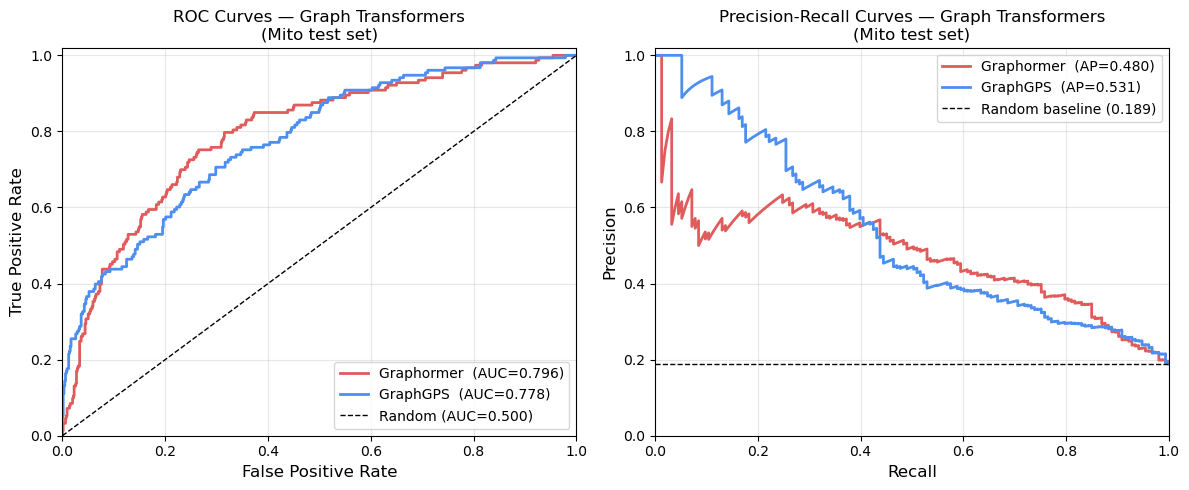

Figure saved → roc_pr_graph_transformers.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── ROC curves ───────────────────────────────────────────────────────────────
ax = axes[0]
colors = {'Graphormer': '#e05c5c', 'GraphGPS': '#4c8ff0'}
for label, y_score, roc in [
    ('Graphormer', graphormer_preds, roc_graphormer),
    ('GraphGPS',   gps_preds,        roc_gps),
]:
    fpr, tpr, _ = roc_curve(y_test_binary, y_score)
    ax.plot(fpr, tpr, lw=2, color=colors[label],
            label=f'{label}  (AUC={roc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — Graph Transformers\n(Mito test set)', fontsize=12)
ax.legend(fontsize=10)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
ax.grid(alpha=0.3)

# ── PR curves ────────────────────────────────────────────────────────────────
ax2 = axes[1]
baseline_precision = y_test_binary.mean()

for label, y_score, prc in [
    ('Graphormer', graphormer_preds, prc_graphormer),
    ('GraphGPS',   gps_preds,        prc_gps),
]:
    prec, rec, _ = precision_recall_curve(y_test_binary, y_score)
    ax2.plot(rec, prec, lw=2, color=colors[label],
             label=f'{label}  (AP={prc:.3f})')

ax2.axhline(baseline_precision, color='k', ls='--', lw=1,
            label=f'Random baseline ({baseline_precision:.3f})')
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.set_title('Precision-Recall Curves — Graph Transformers\n(Mito test set)', fontsize=12)
ax2.legend(fontsize=10)
ax2.set_xlim([0, 1]); ax2.set_ylim([0, 1.02])
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('roc_pr_graph_transformers.png', bbox_inches='tight')
plt.show()
print('Figure saved → roc_pr_graph_transformers.png')

### ROC-AUC interpretation

- **ROC-AUC > 0.7** → model meaningfully distinguishes actives from inactives  
- **ROC-AUC ≈ 0.5** → ranking is no better than random  
- **PR-AUC** is more informative when the dataset is imbalanced (many more inactives than actives), which is typical for bioassays

Note: models were trained to minimise MSE on the continuous score, not to maximise ROC-AUC. Training directly on binary classification (BCE + sigmoid) would likely improve these scores.